In [1]:
from pathlib import Path
import sys
import wfdb
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src" / "data_load.py").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_load import  load_noisy_ecg_data , load_noise_data
from src.adaptive_filters import LMS_filter , NLMS_filter , RLS_filter , evaluate_filter_performance

In [2]:

ecg_path = r"C:\Users\Luchitha\Documents\Python\EMD_for_ECG\data\physionet.org\files\mitdb\1.0.0\100"
multiple_noises = [ "bw","ma" , "em"]  # Change this to "ma" or "em" for different noise types

In [3]:
snr = 5

clean_ecg_signal, noise_signal, noisy_ecg_signal, fs , pli= load_noisy_ecg_data(ecg_path, snr , multiple_noises=multiple_noises , PLI=True)

N = min(len(clean_ecg_signal), len(noisy_ecg_signal), len(noise_signal))






In [4]:
lms_ecg_signal = LMS_filter(noisy_ecg_signal, noise_signal, mu=0.001, filter_order=32, N=N)

nlms_ecg_signal = NLMS_filter(noisy_ecg_signal, noise_signal, mu=0.01, filter_order=30, N=N)

rls_ecg_signal = RLS_filter(noisy_ecg_signal, noise_signal, mu=0.99, filter_order=30, N=N)

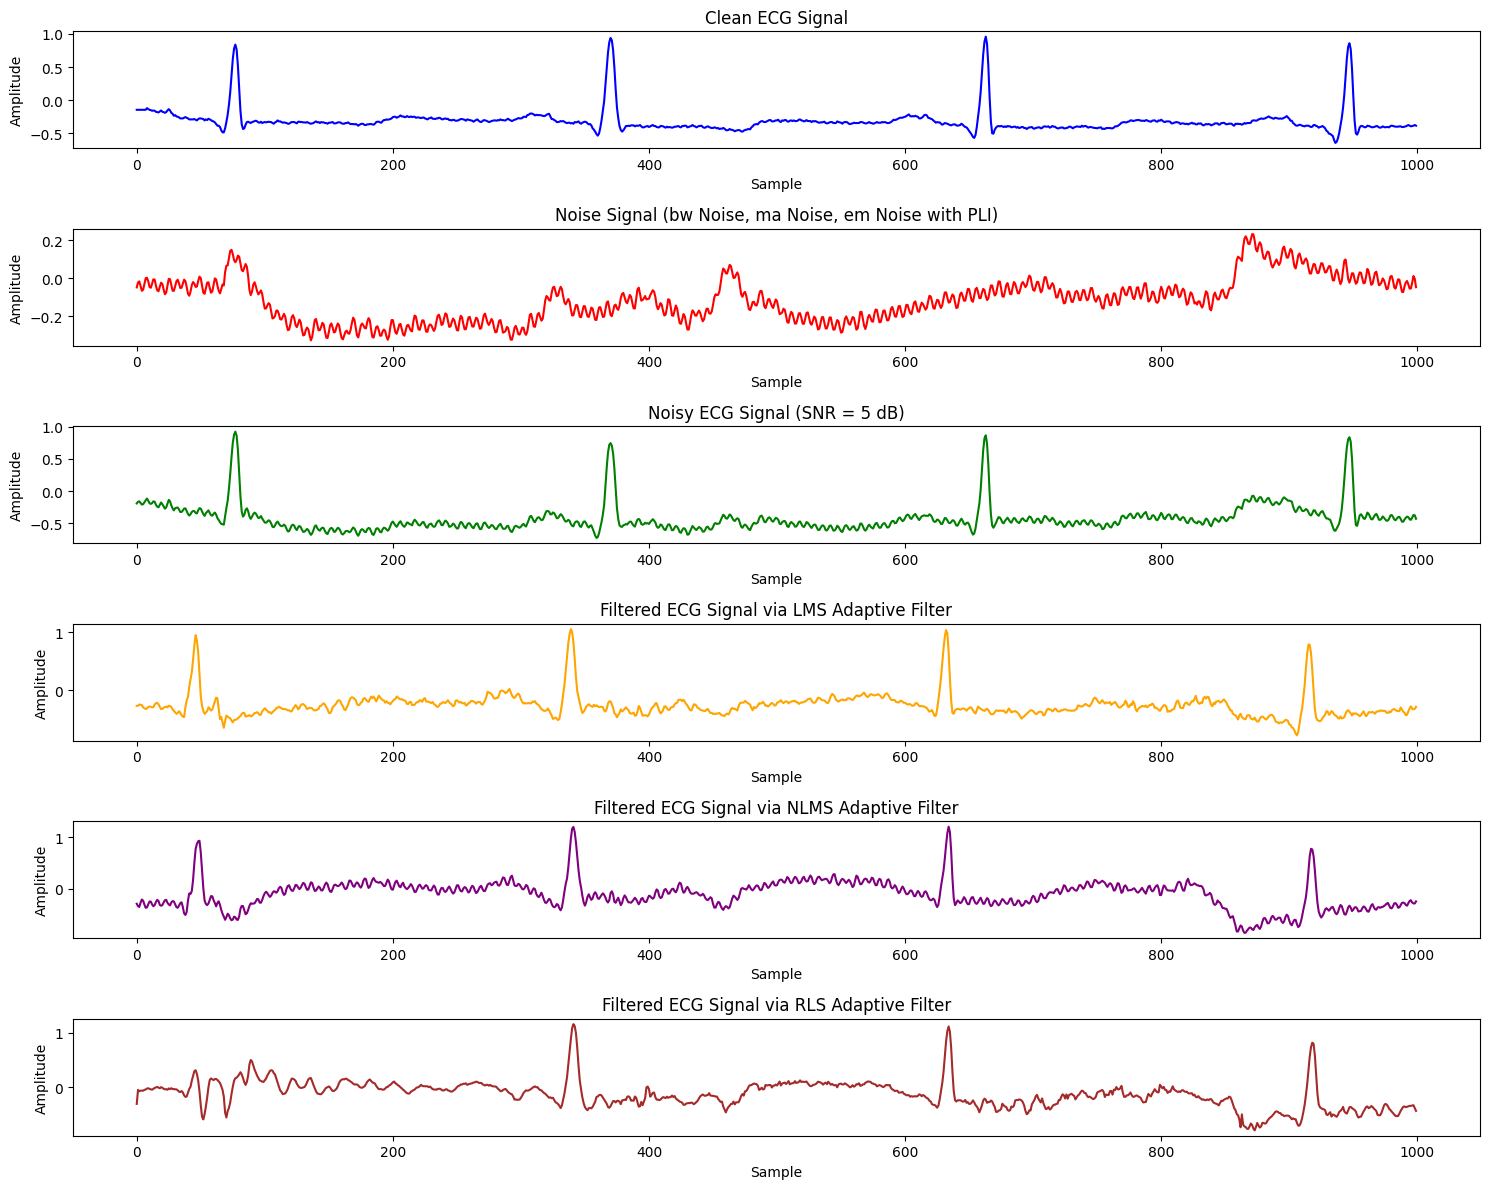

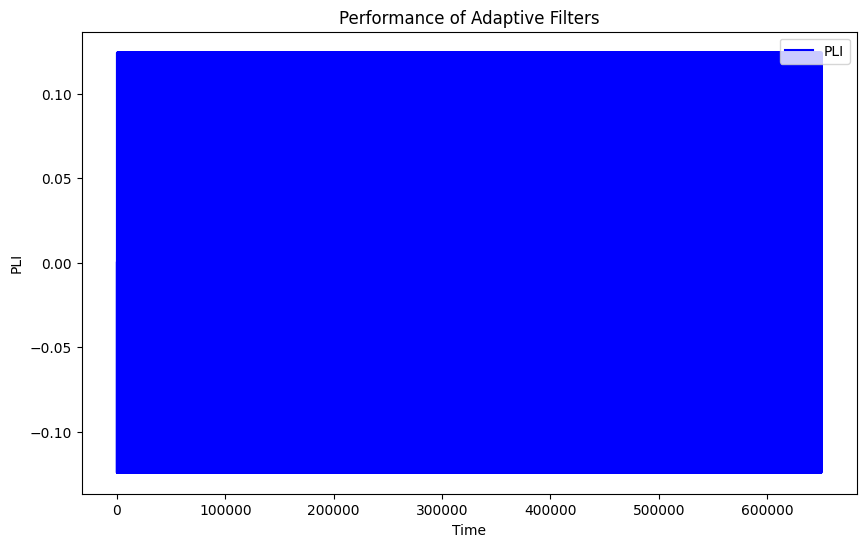

In [5]:


# Plot the clean, noise, and filtered ECG signals
plt.figure(figsize=(15, 12))

# 1. Clean ECG Signal
plt.subplot(6, 1, 1)
plt.plot(clean_ecg_signal[:1000], color='blue')
plt.title('Clean ECG Signal')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# 2. Noise Signal (Fixed subplot grid from 4 to 6)
plt.subplot(6, 1, 2)
plt.plot(noise_signal[:1000], color='red')
plt.title(f'Noise Signal ({", ".join(n + " Noise" for n in multiple_noises)} with {"PLI" if len(pli) > 0 else "No PLI"})')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# 3. Noisy ECG Signal
plt.subplot(6, 1, 3)
plt.plot(noisy_ecg_signal[:1000], color='green')
plt.title(f'Noisy ECG Signal (SNR = {snr} dB)')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# 4. LMS Adaptive Filter Output
plt.subplot(6, 1, 4)
plt.plot(lms_ecg_signal[:1000], color='orange')
plt.title('Filtered ECG Signal via LMS Adaptive Filter')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# 5. NLMS Adaptive Filter Output
plt.subplot(6, 1, 5)
plt.plot(nlms_ecg_signal[:1000], color='purple')  # Changed color to distinguish from LMS
plt.title('Filtered ECG Signal via NLMS Adaptive Filter')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# 6. RLS Adaptive Filter Output
plt.subplot(6, 1, 6)
plt.plot(rls_ecg_signal[:1000], color='brown')   # Changed color to distinguish from LMS/NLMS
plt.title('Filtered ECG Signal via RLS Adaptive Filter')
plt.xlabel('Sample')
plt.ylabel('Amplitude')

# Optimize layout spacing
plt.tight_layout()
plt.show()

# plot the pli noise signal
plt.figure(figsize=(10, 6))
plt.plot(pli, label='PLI', color='blue')
plt.xlabel('Time')
plt.ylabel('PLI')
plt.title('Performance of Adaptive Filters')
plt.legend()
plt.show()


# Adaptive filter performance evaluation

In [9]:
# Evaluae the performance of the adaptive filters

noises = ["bw" , "ma", "em"]

snr = 10

path = r"C:\Users\Luchitha\Documents\Python\EMD_for_ECG\data\physionet.org\files\mitdb\1.0.0\203"

clean_ecg_signal, noise_signal, noisy_ecg_signal, fs , pli = load_noisy_ecg_data(path, snr , multiple_noises=multiple_noises , PLI=True)

N = min(len(clean_ecg_signal), len(noisy_ecg_signal), len(noise_signal))

lms_ecg_signal = LMS_filter(noisy_ecg_signal, noise_signal, mu=0.01, filter_order=32, N=N)

nlms_ecg_signal = NLMS_filter(noisy_ecg_signal, noise_signal, mu=0.1, filter_order=30, N=N)

rls_ecg_signal = RLS_filter(noisy_ecg_signal, noise_signal, mu=0.99, filter_order=30, N=N, eps = 0.1)

# LMS Filter Performance Evaluation
lms_snr, lms_rmse, lms_snr_improvement = evaluate_filter_performance(clean_ecg_signal, lms_ecg_signal, noise_signal)

# NLMS Filter Performance Evaluation
nlms_snr, nlms_rmse, nlms_snr_improvement = evaluate_filter_performance(clean_ecg_signal, nlms_ecg_signal, noise_signal)

# RLS Filter Performance Evaluation
rls_snr, rls_rmse, rls_snr_improvement = evaluate_filter_performance(clean_ecg_signal, rls_ecg_signal, noise_signal)




In [11]:
print("LMS Filter Performance:")
print(f"Output SNR: {lms_snr:.4f} dB")
print(f"Output RMSE: {lms_rmse:.4f}")
print(f"SNR Improvement: {lms_snr_improvement:.4f} dB")

print("\nNLMS Filter Performance:")
print(f"Output SNR: {nlms_snr:.4f} dB")
print(f"Output RMSE: {nlms_rmse:.4f}")
print(f"SNR Improvement: {nlms_snr_improvement:.4f} dB")

print("\nRLS Filter Performance:")
print(f"Output SNR: {rls_snr:.4f} dB")
print(f"Output RMSE: {rls_rmse:.4f}")
print(f"SNR Improvement: {rls_snr_improvement:.4f} dB")

LMS Filter Performance:
Output SNR: 8.2461 dB
Output RMSE: 0.2027
SNR Improvement: -1.7538 dB

NLMS Filter Performance:
Output SNR: 1.5640 dB
Output RMSE: 0.4374
SNR Improvement: -8.4360 dB

RLS Filter Performance:
Output SNR: 5.1169 dB
Output RMSE: 0.2906
SNR Improvement: -4.8830 dB


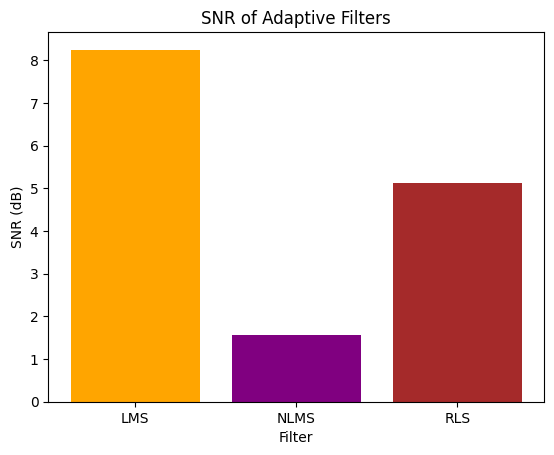

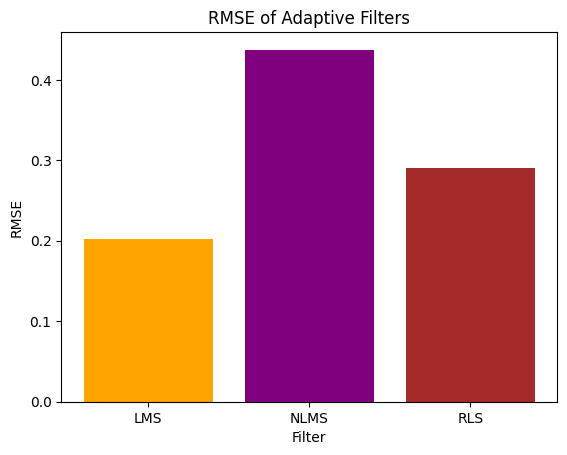

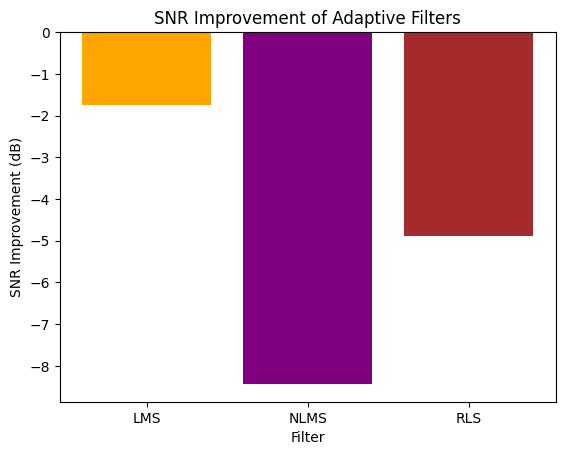

In [12]:
# plot the performance metrics for each filter
filters = ['LMS', 'NLMS', 'RLS']

# plot the SNR for each filter
snr_values = [lms_snr, nlms_snr, rls_snr]
plt.bar(filters, snr_values, color=['orange', 'purple', 'brown'])
plt.xlabel('Filter')
plt.ylabel('SNR (dB)')
plt.title('SNR of Adaptive Filters')
plt.show()

# plot the RMSE for each filter
rmse_values = [lms_rmse, nlms_rmse, rls_rmse]
plt.bar(filters, rmse_values, color=['orange', 'purple', 'brown'])
plt.xlabel('Filter')
plt.ylabel('RMSE')
plt.title('RMSE of Adaptive Filters')
plt.show()

#plot the SNR improvement for each filter
snr_improvement_values = [lms_snr_improvement, nlms_snr_improvement, rls_snr_improvement]
plt.bar(filters, snr_improvement_values, color=['orange', 'purple', 'brown'])
plt.xlabel('Filter')
plt.ylabel('SNR Improvement (dB)')
plt.title('SNR Improvement of Adaptive Filters')
plt.show()